
# Distribution Analysis

## Objective
To understand the distribution of numerical variables using histograms, KDE plots, summary statistics, skewness, and kurtosis.

## Dataset
`ml_training_data.csv`

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn



## 1. What is Distribution Analysis?

Distribution analysis helps us understand how numerical values are spread across a dataset.

It helps us identify:
- Where most values are concentrated.
- Whether data is symmetric or skewed.
- Whether extreme values are present.
- How the shape of data may affect machine learning models.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


In [2]:

import os

file_paths = [
    "ml_training_data.csv",
    r"C:\Users\giris\ml_training_data.csv",
    r"C:\Users\giris\OneDrive\Desktop\sprint-4\ml_training_data.csv"
]

file_path = next((path for path in file_paths if os.path.exists(path)), None)

if file_path is None:
    raise FileNotFoundError(
        "Dataset not found. Check the location of ml_training_data.csv."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()


Dataset loaded successfully!
Shape: (5, 3)


,Study_Hours,Attendance,Exam_Marks
0,2,60,50
1,3,65,55
2,4,75,65
3,5,85,75
4,6,95,90



## 2. Inspect the Numerical Features

We will analyze the numerical columns in the dataset because distribution analysis mainly focuses on numerical values.


In [3]:

numerical_df = df.select_dtypes(include=np.number)

print("Numerical columns:")
print(numerical_df.columns.tolist())

print("\nNumber of numerical columns:", numerical_df.shape[1])
numerical_df.describe()


Numerical columns:
['Study_Hours', 'Attendance', 'Exam_Marks']

Number of numerical columns: 3


,Study_Hours,Attendance,Exam_Marks
count,5.000000,5.000000,5.000000
mean,4.000000,76.000000,67.000000
std,1.581139,14.317821,16.046807
min,2.000000,60.000000,50.000000
25%,3.000000,65.000000,55.000000
50%,4.000000,75.000000,65.000000
75%,5.000000,85.000000,75.000000
max,6.000000,95.000000,90.000000



## 3. Histograms

A histogram shows how frequently values occur within different ranges.

It helps us understand the spread and shape of a numerical variable.


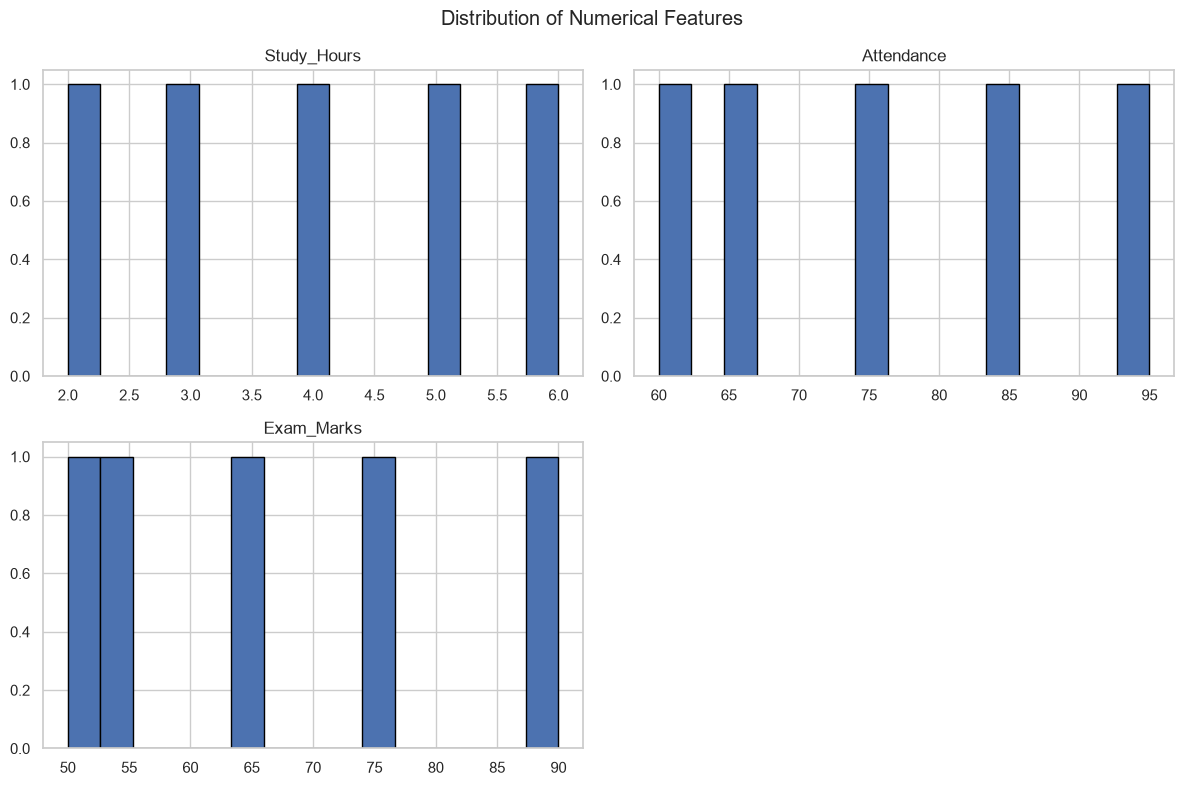

In [4]:
if numerical_df.shape[1] == 0:
    print("No numerical columns are available.")
else:
    numerical_df.hist(figsize=(12, 8), bins=15, edgecolor="black")
    plt.suptitle("Distribution of Numerical Features")
    plt.tight_layout()
    plt.show()


## 4. KDE Plots

KDE stands for Kernel Density Estimation. It shows a smooth curve representing the shape of a numerical distribution.

It helps us see where values are concentrated.


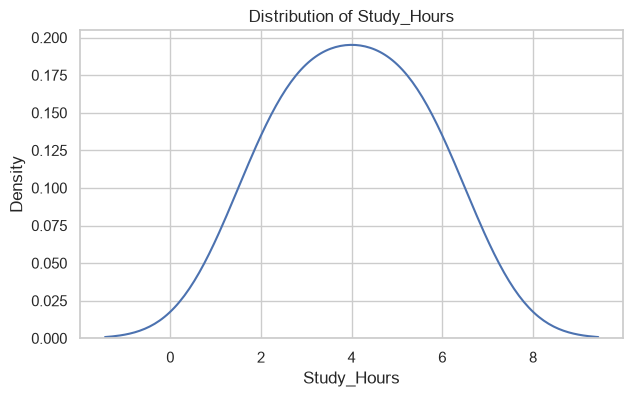

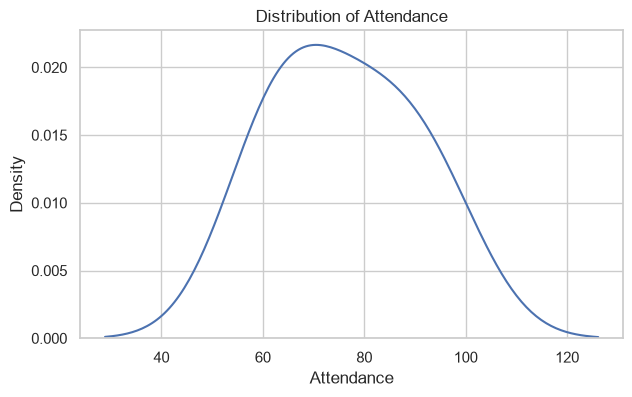

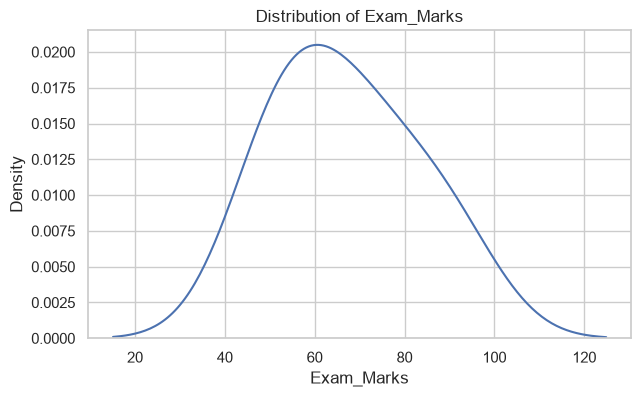

In [5]:

for column in numerical_df.columns:
    values = numerical_df[column].dropna()

    if len(values) > 1 and values.nunique() > 1:
        plt.figure(figsize=(7, 4))
        sns.kdeplot(x=values)
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Density")
        plt.show()
    else:
        print(f"Skipping KDE for {column}: not enough distinct values.")


## 5. Mean and Median Comparison

The mean is the average of the values, while the median is the middle value.

Comparing them can help us understand the shape of a distribution. A large difference may indicate skewness, although it does not prove it by itself.


In [6]:
summary = pd.DataFrame({
    "Mean": numerical_df.mean(),
    "Median": numerical_df.median(),
    "Standard Deviation": numerical_df.std()
})

summary


,Mean,Median,Standard Deviation
Study_Hours,4.0,4.0,1.581139
Attendance,76.0,75.0,14.317821
Exam_Marks,67.0,65.0,16.046807


## 6. Skewness

Skewness measures the asymmetry of a distribution.

- Skewness near 0: approximately symmetric.
- Positive skewness: a longer tail toward higher values.
- Negative skewness: a longer tail toward lower values.

These are general guidelines; interpretation also depends on the histogram and the data.


In [7]:
skewness = numerical_df.skew()

print("Skewness of numerical features:")
display(skewness.to_frame(name="Skewness"))

for column, value in skewness.items():
    if pd.isna(value):
        interpretation = "Cannot calculate"
    elif value > 0.5:
        interpretation = "Positively skewed"
    elif value < -0.5:
        interpretation = "Negatively skewed"
    else:
        interpretation = "Approximately symmetric"

    print(f"{column}: {interpretation}")


Skewness of numerical features:


,Skewness
Study_Hours,0.000000
Attendance,0.306628
Exam_Marks,0.608051


Study_Hours: Approximately symmetric
Attendance: Approximately symmetric
Exam_Marks: Positively skewed


## 7. Kurtosis

Kurtosis describes aspects of a distribution's tail heaviness compared with a normal distribution.

Pandas calculates excess kurtosis:
- Near 0: similar kurtosis to a normal distribution.
- Positive: heavier tails may be present.
- Negative: lighter tails may be present.

Kurtosis should be interpreted together with plots and other statistics.


In [8]:
kurtosis = numerical_df.kurt()

print("Excess kurtosis of numerical features:")
display(kurtosis.to_frame(name="Kurtosis"))


Excess kurtosis of numerical features:


,Kurtosis
Study_Hours,-1.200000
Attendance,-1.543724
Exam_Marks,-0.681497


## 8. Distribution Summary

We will combine descriptive statistics, skewness, and kurtosis to compare the numerical features.


In [9]:
distribution_summary = numerical_df.describe().T

distribution_summary["Skewness"] = numerical_df.skew()
distribution_summary["Kurtosis"] = numerical_df.kurt()

distribution_summary


,count,mean,std,min,25%,50%,75%,max,Skewness,Kurtosis
Study_Hours,5.0,4.0,1.581139,2.0,3.0,4.0,5.0,6.0,0.000000,-1.200000
Attendance,5.0,76.0,14.317821,60.0,65.0,75.0,85.0,95.0,0.306628,-1.543724
Exam_Marks,5.0,67.0,16.046807,50.0,55.0,65.0,75.0,90.0,0.608051,-0.681497



## 9. Observations and Insights

- Compared the mean and median of the numerical features to understand their distributions.
- Used histograms to observe how the values are spread.
- Analyzed skewness to identify whether the features are approximately symmetric, positively skewed, or negatively skewed.
- Examined kurtosis to understand the tail behavior of the distributions.
- Compared the standard deviations to identify which feature has the greatest spread.

### Conclusion
Distribution analysis helps us understand the shape, spread, and patterns of numerical data. These findings can help guide data preprocessing and machine learning decisions.
